# GAMERA + Gammapy Jupyter Notebook Tutorial


## Overview

This notebook tutorial teaches users how to combine GAMERA — an open-source C++/Python for spectral modelling of non-thermally emitting astrophysical sources — with the Gammapy analysis framework to model and fit high-energy source spectra.

GAMERA's Python module is called **`gappa`** (built via SWIG); all API calls in this tutorial use `import gappa`.



## Tutorial 1 — Environment Setup & Building gappa

Follow the steps in the first tutorial

**Note that if you already have a jupyter notebook instance running, you will have to re-start it after installing GAMERA and adding it to the PYTHONPATH**

## A note on units
Units in GAMERA are mostly in cgs, with several exceptions that are meaningful in the astrophysical context.

    times are in years, except for particle escape time scales
    lengths are in parsecs
    when retrieving SEDs, for convenience the units are
        erg / s / cm2 vs TeV for radiation flux SEDs
        erg / s vs. TeV for luminosity SEDs (i.e. when the distance to the source is not set)
        erg vs. TeV for particle SEDs

    (differential spectra are again in cgs units)
    gas densities are in number densities.

Also, the units of the spectrum will impact the unit of the calculated radiation spectra. For instance, if the unit of the particle spectrum is only differential in energy, i.e. 1/erg, the output radiation spectra will have the unit of a flux if a source distance is specified (see below) or differential photon count per energy and time if not.

On the other hand, if the input unit is differential also in volume, i.e. 1/erg/cm3, then also the output radiation spectrum will be. Therefore, if no distance is specified in this case, a volume photon emissivity will be calculated, i.e. d3N/dEdVdt.

## Tutorial 2 — Interfacing with Gammapy


Now that you know how to use GAMERA, interfacing with gammapy is very easy and just requires constructing a custom model.


In [1]:
import gappa as gp
import numpy as np
import astropy.units as u
from gammapy.maps import MapAxis
import matplotlib.pyplot as plt


### First define the models
 We will make two custom models: a hadronic and a leptonic one. But you can mix (like we did above) or do whatever you need.

The new model has to be added to the SPECTRAL_MODEL_REGISTRY of Gammapy

In [2]:
from gammapy.modeling import Parameter
from gammapy.modeling.models import (
    SpectralModel,
    SPECTRAL_MODEL_REGISTRY,
)


For the leptonic model we include synchrotron and IC

In [3]:
class leptonic_model(SpectralModel):
    """Wrapper of GAMERA synchrotron and IC emission.
    A power law with cutoff is assumed for the electron spectrum.
    To limit the span of the parameters space, we fit the log10 of the parameters
    whose range is expected to cover several orders of magnitudes.

    Some of the parameters (like the distance) should not be fit, but are there just to evaluate the model.
    """

    tag = ["leptonic", "lg"]
    # parameters that we actually might want to fit
    B = Parameter("B", 1*u.uG, min=0.1, max=100) #in uGauss
    index = Parameter("index", 2, min=1.5, max=4.0) #it's positive: E^-index
    effic = Parameter("effic", 1e-4, min=1e-8, max=1, interp='log') # fraction of Ltot into electrons

    E_min = Parameter("E_min", "1e-5 TeV", min=1e-9, max=10, interp='log', frozen=True) # in TeV
    E_cut = Parameter("E_cut", "1e3 TeV", min=1, max=1e5, interp='log', frozen=True)  # in TeV

    # parameters that we should not fit but just provide
    L_tot = Parameter("L_tot", "5e38 erg s-1", min=1e30, max=1e50, frozen=True, interp='log', scale_method="scale10") # in ergs/s
    d = Parameter("d", "2 kpc", min=1, max=10, frozen=True) # in kpc
    age = Parameter("age", "2e3 yr", min=1e3, max=1e6, frozen=True, interp='log')


    @staticmethod
    def evaluate(
        energy,
        B,
        index,
        effic,
        E_min,
        E_cut,
        L_tot,
        d,
        age,
    ):
        # Get the relevant GAMERA modules
        fu = gp.Utils()
        # GAMERA doesn't know about astropy units
        # so we need to get everything in the right unit
        # and as a normal float and not a quantity
        b_field = B.to_value('G')
        age = age.to_value('yr')
        distance = d.to_value('pc')
        e_cut = np.log10(E_cut.to_value('erg'))
        e_min = np.log10(E_min.to_value('erg'))
        norm = (effic * L_tot).to_value('erg s-1')
        photon_energies = energy.flatten().to_value('erg')
        index = index.value

        # Define the electron energy range and the injected spectrum
        # We want to go beyond the cutoff so we use two orders of magnitude more than e_cut
        energy_electrons_edges = np.logspace(e_min, e_cut+2, 200+1) # it's in ergs

        energy_electrons = MapAxis.from_edges(energy_electrons_edges, interp='log', unit='erg')
        exp_cutoff = np.exp(-(energy_electrons.center.to('erg')/E_cut.to('erg')).value)
        power_law = (energy_electrons.center.to_value('erg') ** -index)*exp_cutoff


        # Bundle together in the way GAMERA wants
        power_law_spectrum = np.array(list(zip(energy_electrons.center.to_value('erg'), power_law)))

        fp = gp.Particles()
        fp.ToggleQuietMode()
        fp.SetSolverMethod(1)

        fp.SetBField(b_field)
        fp.SetAge(age)
        fp.SetCustomInjectionSpectrum(power_law_spectrum)
        # Normalize to total power
        fp.SetLuminosity(norm)

        # We fix the CMB as only photon target
        T = 2.7*u.K
        edens = 0.26*u.eV*u.cm**-3
        fp.AddThermalTargetPhotons(T.to_value('K'),edens.to_value('erg cm-3'),500)

        # But note that you can add an arbitrary one from an array
        #fp.AddArbitraryTargetPhotons(RADIATION_FIELD)
            
        fp.CalculateElectronSpectrum()
        sp = np.array(fp.GetParticleSpectrum())  # returns diff. spectrum: E(erg) vs dN/dE (1/erg)
        sed = np.array(fp.GetParticleSED())# returns SED: E(TeV) vs E**2*dN/dE (erg)
    
    
        fr = gp.Radiation()
        fr.ToggleQuietMode()
        fr.SetElectrons(sp)
        fr.AddArbitraryTargetPhotons(fp.GetTargetPhotons()) # output from 'Particles' is in the right format to be used in 'Radiation'
        fr.SetDistance(distance)
        fr.SetBField(b_field)


        # compute the spectrum on the points given by the data
        fr.CalculateDifferentialPhotonSpectrum(photon_energies)
        rad = np.array(fr.GetTotalSED())  # this is (E^2*dN/dE vs E, units: erg / cm^2 / s vs TeV)

        # if the energy requested is outside of the range of the SEDs we just return 0
        if len(rad)==0:
            return np.zeros(len(photon_energies))*u.cm**-2*u.eV**-1*u.s**-1
        sed = rad[:,1]


        # Get back to the world of units
        sed *= u.erg * u.cm**-2 *u.s **-1

        result = (sed / ((rad[:,0]*u.TeV) ** 2)).to("1 / (cm2 eV s)")
        result = np.reshape(result, energy.shape)

        return result


# IMPORTANT: add the new custom model to the registry of spectral models recognised by gammapy
SPECTRAL_MODEL_REGISTRY.append(leptonic_model)

You can now use it as any other gammapy model

Task was destroyed but it is pending!
task: <Task pending name='Task-41' coro=<_async_in_context.<locals>.run_in_context() running at /home/nieto/mambaforge/envs/gammapy-2.1/lib/python3.12/site-packages/ipykernel/utils.py:57> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/nieto/mambaforge/envs/gammapy-2.1/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/nieto/mambaforge/envs/gammapy-2.1/lib/python3.12/asyncio/base_events.py:716: RuntimeWarning: coroutine '_async_in_context.<locals>.run_in_context' was never awaited
  self._ready.clear()


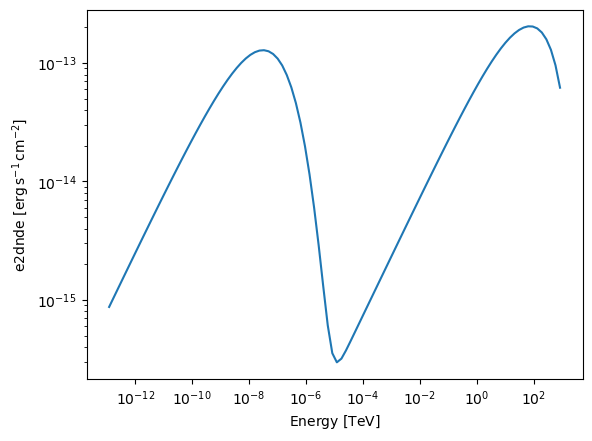

In [4]:
ll = leptonic_model()
ll.plot(energy_bounds=[1e-13,1e3]*u.TeV, sed_type='e2dnde')
plt.show()

For the hadronic model only pp will be relevant because the only target we will set is the CMB

In [5]:
class hadronic_model(SpectralModel):
    """Wrapper of GAMERA pp emission.
    A power law with cutoff is assumed for the proton spectrum.
    To limit the span of the parameters space, we fit the log10 of the parameters
    whose range is expected to cover several orders of magnitudes.

    Some of the parameters (like the distance) should not be fit, but are there just to evaluate the model.
    """

    tag = ["hadronic", "hg"]
    # parameters that we actually might want to fit
    B = Parameter("B", 1*u.uG, min=0.1, max=100) #in uGauss
    index = Parameter("index", 2, min=1.5, max=4.0) #it's positive: E^-index
    effic = Parameter("effic", 1e-4, min=1e-8, max=1, interp='log')

    E_min = Parameter("E_min", "1e-3 TeV", min=1e-9, max=10, interp='log', frozen=True) # in TeV
    E_cut = Parameter("E_cut", "1e3 TeV", min=1, max=1e5, interp='log', frozen=True)  # in TeV

    # parameters that we should not fit but just provide
    L_tot = Parameter("L_tot", "5e38 erg s-1", min=1e30, max=1e50, frozen=True, interp='log', scale_method="scale10") # in ergs/s
    d = Parameter("d", "2 kpc", min=1, max=10, frozen=True) # in kpc
    age = Parameter("age", "1e6 yr", min=1e3, max=1e10, frozen=True, interp='log')
    ambient_density = Parameter("ambient_density", "1cm-3", min=1e-4, max=1e4, frozen=True)


    @staticmethod
    def evaluate(
        energy,
        B,
        index,
        effic,
        E_min,
        E_cut,
        L_tot,
        d,
        age,
        ambient_density,
    ):

        # Get the relevant GAMERA modules
        fu = gp.Utils()
        fp = gp.Particles()
        fp.ToggleQuietMode()
        fp.SetSolverMethod(1)


        # GAMERA doesn't know about astropy units
        # so we need to get everything in the right unit
        # and as a normal float and not a quantity
        b_field = B.to_value('G')
        age = age.to_value('yr')
        distance = d.to_value('pc')
        e_cut = np.log10(E_cut.to_value('erg'))
        e_min = np.log10(E_min.to_value('erg'))
        norm = (effic * L_tot).to_value('erg s-1')
        photon_energies = energy.flatten().to_value('erg')
        index = index.value
        ambient_density = ambient_density.to_value('cm-3')

        # Define the electron energy range and the injected spectrum
        # We want to go beyond the cutoff so we use two orders of magnitude more than e_cut
        energy_protons_edges = np.logspace(e_min, e_cut+2, 200+1) # it's in ergs


        energy_protons = MapAxis.from_edges(energy_protons_edges, interp='log', unit='erg')
        exp_cutoff = np.exp(-(energy_protons.center.to('erg')/E_cut.to('erg')).value)
        power_law = (energy_protons.center.to_value('erg') ** -index)*exp_cutoff

        # Bundle together in the way GAMERA wants
        power_law_spectrum = np.array(list(zip(energy_protons.center.to_value('erg'), power_law)))



        fp.SetBField(b_field)
        fp.SetAge(age)
        fp.SetCustomInjectionSpectrum(power_law_spectrum)
           
        # Normalize to total power
        fp.SetLuminosity(norm)

        # Set ambient density
        fp.SetAmbientDensity(ambient_density)
            
        fp.CalculateProtonSpectrum()
        sp = np.array(fp.GetParticleSpectrum())  # returns diff. spectrum: E(erg) vs dN/dE (1/erg)
        sed = np.array(fp.GetParticleSED())# returns SED: E(TeV) vs E**2*dN/dE (erg)
    
    
        fr = gp.Radiation()
        fr.ToggleQuietMode()
        fr.SetProtons(sp)
        fr.SetAmbientDensity(ambient_density)
        fr.SetDistance(distance)
        fr.SetBField(b_field)



        # compute the spectrum on the points given by the data
        fr.CalculateDifferentialPhotonSpectrum(photon_energies)
        rad = np.array(fr.GetTotalSED())  # this is (E^2*dN/dE vs E, units: erg / cm^2 / s vs TeV)

        # if the energy requested is outside of the range of the SEDs we just return 0
        if len(rad)==0:
            return np.zeros(len(photon_energies))*u.cm**-2*u.eV**-1*u.s**-1
        sed = rad[:,1]

        # Get back to the world of units
        sed *= u.erg * u.cm**-2 *u.s **-1

        result = (sed / ((rad[:,0]*u.TeV) ** 2)).to("1 / (cm2 eV s)")
        result = np.reshape(result, energy.shape)

        return result

SPECTRAL_MODEL_REGISTRY.append(hadronic_model)

and same as before

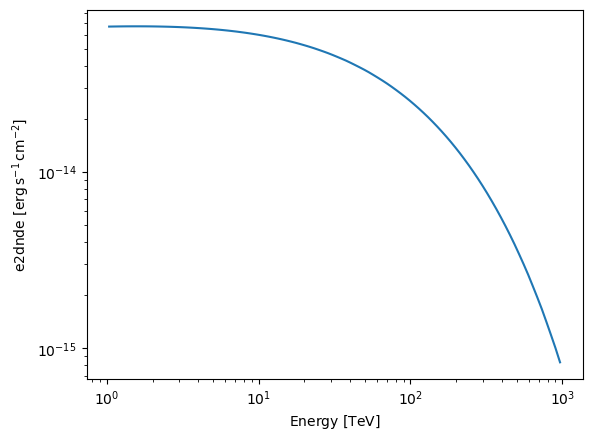

In [6]:
hh = hadronic_model()
hh.plot(energy_bounds=[1,1e3]*u.TeV, sed_type='e2dnde')
plt.show()

### Get data to fit
These steps are basically lifted from the corresponding [gammapy tutorial](https://docs.gammapy.org/2.0/tutorials/analysis-1d/spectral_analysis.html)

In [7]:
from pathlib import Path
from astropy.coordinates import Angle, SkyCoord
from regions import CircleSkyRegion

from gammapy.data import DataStore
from gammapy.datasets import (
    Datasets,
    FluxPointsDataset,
    SpectrumDataset,
)
from gammapy.estimators import FluxPointsEstimator
from gammapy.makers import (
    ReflectedRegionsBackgroundMaker,
    SafeMaskMaker,
    SpectrumDatasetMaker,
)
from gammapy.maps import MapAxis, RegionGeom, WcsGeom


In [8]:
datastore = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1/")
obs_ids = [23523, 23526, 23559, 23592]
observations = datastore.get_observations(obs_ids)

target_position = SkyCoord(ra=83.63, dec=22.01, unit="deg", frame="icrs")
on_region_radius = Angle("0.11 deg")
on_region = CircleSkyRegion(center=target_position, radius=on_region_radius)

exclusion_region = CircleSkyRegion(
    center=SkyCoord(183.604, -8.708, unit="deg", frame="galactic"),
    radius=0.5 * u.deg,
)

skydir = target_position.galactic
geom = WcsGeom.create(
    npix=(150, 150), binsz=0.05, skydir=skydir, proj="TAN", frame="icrs"
)

exclusion_mask = ~geom.region_mask([exclusion_region])

energy_axis = MapAxis.from_energy_bounds(
    0.1, 40, nbin=10, per_decade=True, unit="TeV", name="energy"
)
energy_axis_true = MapAxis.from_energy_bounds(
    0.05, 100, nbin=20, per_decade=True, unit="TeV", name="energy_true"
)

geom = RegionGeom.create(region=on_region, axes=[energy_axis])
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker(exclusion_mask=exclusion_mask)
safe_mask_maker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=10)

datasets = Datasets()

for obs_id, observation in zip(obs_ids, observations):
    dataset = dataset_maker.run(dataset_empty.copy(name=str(obs_id)), observation)
    dataset_on_off = bkg_maker.run(dataset, observation)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, observation)
    datasets.append(dataset_on_off)

print(datasets)

dataset_stacked = Datasets(datasets).stack_reduce()

Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : 23523
  Instrument : HESS
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : 23526
  Instrument : HESS
  Models     : 

Dataset 2: 

  Type       : SpectrumDatasetOnOff
  Name       : 23559
  Instrument : HESS
  Models     : 

Dataset 3: 

  Type       : SpectrumDatasetOnOff
  Name       : 23592
  Instrument : HESS
  Models     : 




### Set up the model
We will fix B because we are not fitting to any X-ray data

In [9]:
from gammapy.modeling.models import (
    SkyModel,
    UniformPrior,
    LogUniformPrior,
)

from gammapy.modeling.sampler import Sampler
import os 

In [10]:
hadronic_parameters = {
    "B" : 100*u.uG, # G
    "index"   : 2.14, # I fitted it and now it is fixed for performance
    "effic" : 0.06,
    "age" : 2e5*u.yr,
    "E_min" : 1*u.GeV,
    "E_cut" : 1*u.PeV, # freeze to 0.019 if running the fit on the notebook is too slow
    "L_tot" : 5e38*u.erg/u.s, 
    "d" : 2*u.kpc,
    "ambient_density" : 100*u.cm**-3
}

hadro = hadronic_model()

hadro.B.frozen = True


hadro.E_cut.frozen = False
hadro.index.frozen = True # I fitted it and now it is fixed for performance
hadro.effic.frozen = False

hadro.E_cut.error = 0.5
hadro.index.error = 0.1
hadro.effic.error = 0.01

hadro.E_cut.prior = LogUniformPrior(min=1e-2, max=1e3)
hadro.index.prior = UniformPrior(min=1, max=3)
hadro.effic.prior = LogUniformPrior(min=1e-4, max=1)


for k in hadronic_parameters.keys():
    hadro.parameters[k].quantity = hadronic_parameters[k]

hadro_model = SkyModel(spectral_model = hadro.copy(), name='hadronic')
dataset_stacked.models = hadro_model

sampler_opts = {
    "live_points": 100,
    "frac_remain": 0.1,
    "log_dir": None,
}

sampler = Sampler(backend="ultranest", sampler_opts=sampler_opts)

result_hadronic = sampler.run(dataset_stacked)



[ultranest] Sampling 100 live points from prior ...


[ultranest] Explored until L=-4  33 [-4.4146..-4.4142]*| it/evals=982/1692 eff=61.6834% N=100          0 
[ultranest] Likelihood function evaluations: 1696
[ultranest]   logZ = -11.94 +- 0.2279
[ultranest] Effective samples strategy wants to improve: -10.07..-4.33 (ESS = 398.1, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.44+-0.15 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy wants 98 minimum live points (dlogz from 0.19 to 0.64, need <0.5)
[ultranest]   logZ error budget: single: 0.26 bs:0.23 tail:0.09 total:0.25 required:<0.50
[ultranest] Widening from 100 to 200 live points before L=-1e+01...
[ultranest] Will add 100 live points (x1) at L=-3e+02 ...
[ultranest] Exploring (in particular: L=-336.03..-4.34) ...
[ultranest] Explored until L=-4  33 [-336.0262..-4.3350] | it/evals=2310/3792 eff=68.0344% N=200  
[ultranest] Likelihood function evaluations: 3792
[ultranest]   logZ = -11.98 +- 0.1573
[ultranest] Effective samples strategy satisfi

<Figure size 3000x3000 with 0 Axes>

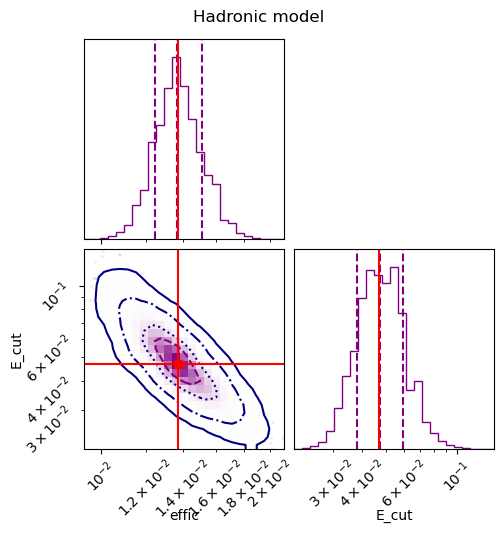

In [11]:
from ultranest.plot import cornerplot

plt.figure(figsize=(30,30))
fig = cornerplot(
    result_hadronic.sampler_results,
    plot_datapoints=True,
    plot_density=True,
    bins=25,
    title_fmt=".2f",
    with_legend=False,
    smooth=True,
    axes_scale=['log', 'log'],
    truths = result_hadronic.sampler_results["maximum_likelihood"]["point"],
    truth_color="red",
    show_titles=False,
)
fig.suptitle("Hadronic model")

plt.show()


In [12]:
fpe = FluxPointsEstimator(
    energy_edges=energy_axis.downsample(3).edges, source="hadronic", selection_optional="all"
)
flux_points = fpe.run(datasets=dataset_stacked)

/home/nieto/mambaforge/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


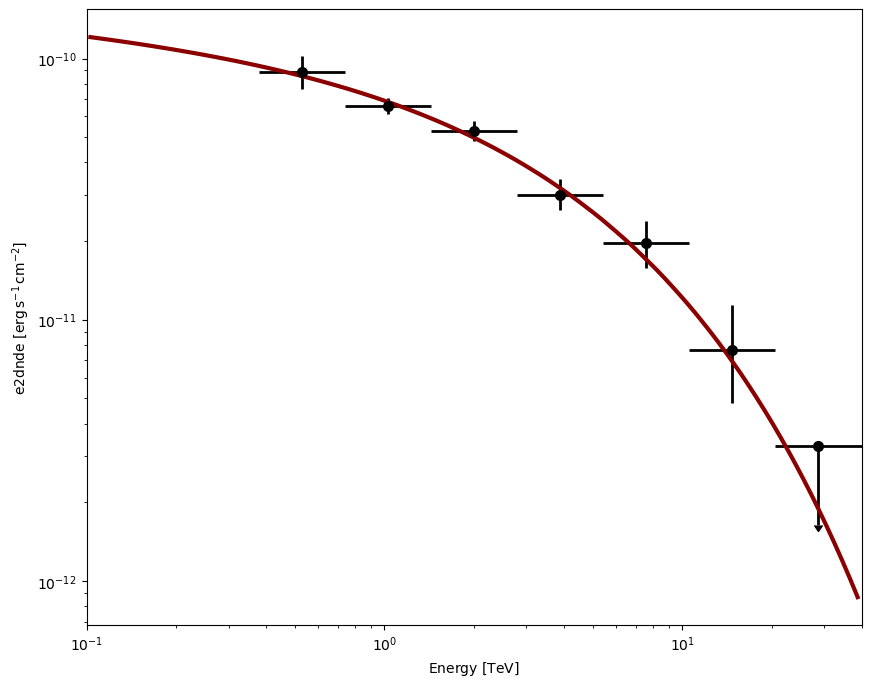

In [13]:
plt.figure(figsize=(10,8))

ax = flux_points.plot(sed_type='e2dnde', color='k', lw=2, marker='o', markersize=7)
dataset_stacked.models[0].spectral_model.plot([0.1,40]*u.TeV, sed_type='e2dnde', ax=ax, color='darkred', lw=3)

plt.show()

The same can be done with the leptonic model but it takes a bit longer so we will comment the fit step

In [14]:

age = 2e5
leptonic_parameters = {
    "B" : 100*u.uG, # uG
    "index"   : 2,
    "effic" : 0.005,
    "age" : age*u.yr,
    "E_min" : 1*u.MeV,
    "E_cut" : 3*u.PeV,
    "L_tot" : 5e38*u.erg/u.s, 
    "d" : 2*u.kpc,
}

lepto = leptonic_model()
lepto.index.error = 0.05
lepto.effic.error = 0.001
lepto.E_cut.error = 0.5

lepto.E_cut.frozen = False
lepto.index.frozen = False
lepto.B.frozen = True
lepto.effic.frozen = False


lepto.effic.prior = LogUniformPrior(min=1e-5, max=1e-1)
lepto.index.prior = UniformPrior(min=0.5, max=3)
lepto.E_cut.prior = LogUniformPrior(min=1e-2, max=1e2)

for k in leptonic_parameters.keys():
    lepto.parameters[k].quantity = leptonic_parameters[k]


lepto_model = SkyModel(spectral_model = lepto.copy(), name='leptonic')
dataset_stacked.models = lepto_model


#result_leptonic = sampler.run(dataset_stacked)